In [1]:
import pandas as pd
import numpy as np

# Load cleaned dataset
df = pd.read_csv("data/processed/cleaned_data.csv")

# Convert date columns
df["transaction_date"] = pd.to_datetime(df["transaction_date"])
df["expiration_date"] = pd.to_datetime(df["expiration_date"])

print("Dataset shape:", df.shape)

# Unique products
print("\nUnique products:", df["product_id"].nunique())

# Unique stores
print("Unique stores:", df["store_id"].nunique())

# Unique transaction dates
print("Unique dates:", df["transaction_date"].nunique())

# Date range
print("Start date:", df["transaction_date"].min())
print("End date:", df["transaction_date"].max())

# Records per product
print("\nRecords per product:")
print(df.groupby("product_id").size().describe())

# Sample records
display(
    df[[
        "product_id",
        "product_name",
        "store_id",
        "transaction_date",
        "daily_demand",
        "initial_quantity"
    ]].head(10)
)

Dataset shape: (100000, 42)

Unique products: 45301
Unique stores: 50
Unique dates: 731
Start date: 2023-01-01 00:00:00
End date: 2024-12-31 00:00:00

Records per product:
count    45301.000000
mean         2.207457
std          1.364630
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         16.000000
dtype: float64


,product_id,product_name,store_id,transaction_date,daily_demand,initial_quantity
0,BAK_DON_743,Donuts,STORE_046,2024-09-25,54,158
1,MEA_SAU_338,Sausages,STORE_030,2023-04-14,55,353
2,BAK_BAG_799,Bagels,STORE_035,2024-10-25,331,483
3,PHA_VAC_801,Vaccines,STORE_003,2023-11-29,7,477
4,REA_FRE_422,Fresh Pasta,STORE_042,2023-08-06,169,391
5,PHA_EYE_369,Eye Drops,STORE_026,2024-08-21,0,270
6,BEV_FRE_873,Fresh Juice,STORE_041,2023-02-18,4,42
7,FRO_FRO_710,Frozen Dinners,STORE_036,2024-04-24,0,463
8,PHA_ANT_887,Antibiotics,STORE_019,2024-10-18,2,379
9,BAK_CRO_880,Croissants,STORE_041,2023-07-02,50,111


In [2]:
# Check unique product-store combinations

df["product_store"] = (
    df["product_id"].astype(str) + "_" +
    df["store_id"].astype(str)
)

print(
    "Unique product-store combinations:",
    df["product_store"].nunique()
)

# Records per product-store combination
combo_counts = df.groupby("product_store").size()

print("\nRecords per product-store combination:")
print(combo_counts.describe())

print(
    "\nCombinations with only one record:",
    (combo_counts == 1).sum()
)

print(
    "Combinations with at least 3 records:",
    (combo_counts >= 3).sum()
)

Unique product-store combinations: 97984

Records per product-store combination:
count    97984.000000
mean         1.020575
std          0.144026
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          3.000000
dtype: float64

Combinations with only one record: 95997
Combinations with at least 3 records: 29


In [3]:
# Records per transaction date
date_counts = df.groupby("transaction_date").size()

print("Records per date:")
print(date_counts.describe())

# Records per store
store_counts = df.groupby("store_id").size()

print("\nRecords per store:")
print(store_counts.describe())

# Check whether product IDs have consistent product names and categories
product_check = df.groupby("product_id").agg(
    product_names=("product_name", "nunique"),
    categories=("category", "nunique")
)

print("\nProducts with multiple names:",
      (product_check["product_names"] > 1).sum())

print("Products with multiple categories:",
      (product_check["categories"] > 1).sum())

Records per date:
count    731.000000
mean     136.798906
std       11.281664
min       98.000000
25%      129.000000
50%      137.000000
75%      144.000000
max      174.000000
dtype: float64

Records per store:
count      50.000000
mean     2000.000000
std        43.004983
min      1877.000000
25%      1980.750000
50%      2000.000000
75%      2032.750000
max      2087.000000
dtype: float64

Products with multiple names: 874
Products with multiple categories: 0


In [4]:
# Find product IDs associated with multiple names
multiple_names = (
    df.groupby("product_id")["product_name"]
    .nunique()
)

problem_product_ids = multiple_names[
    multiple_names > 1
].index

# Display examples
problem_products = (
    df[df["product_id"].isin(problem_product_ids)]
    [["product_id", "product_name", "category"]]
    .drop_duplicates()
    .sort_values("product_id")
)

print("Number of affected product IDs:",
      len(problem_product_ids))

print("\nSample records:")
print(problem_products.head(30).to_string(index=False))

Number of affected product IDs: 874

Sample records:
 product_id      product_name     category
FRO_FRO_100    Frozen Dinners Frozen_Meals
FRO_FRO_100 Frozen Vegetables Frozen_Meals
FRO_FRO_100   Frozen Desserts Frozen_Meals
FRO_FRO_101 Frozen Vegetables Frozen_Meals
FRO_FRO_101    Frozen Dinners Frozen_Meals
FRO_FRO_101   Frozen Desserts Frozen_Meals
FRO_FRO_102 Frozen Vegetables Frozen_Meals
FRO_FRO_102   Frozen Desserts Frozen_Meals
FRO_FRO_102    Frozen Dinners Frozen_Meals
FRO_FRO_103   Frozen Desserts Frozen_Meals
FRO_FRO_103    Frozen Dinners Frozen_Meals
FRO_FRO_104   Frozen Desserts Frozen_Meals
FRO_FRO_104    Frozen Dinners Frozen_Meals
FRO_FRO_104 Frozen Vegetables Frozen_Meals
FRO_FRO_105 Frozen Vegetables Frozen_Meals
FRO_FRO_105    Frozen Dinners Frozen_Meals
FRO_FRO_106 Frozen Vegetables Frozen_Meals
FRO_FRO_106    Frozen Dinners Frozen_Meals
FRO_FRO_106   Frozen Desserts Frozen_Meals
FRO_FRO_107    Frozen Dinners Frozen_Meals
FRO_FRO_107 Frozen Vegetables Frozen_Meals
F

In [5]:
# Check whether each product name belongs to only one category
name_category_check = (
    df.groupby("product_name")["category"]
    .nunique()
)

print(
    "Product names associated with multiple categories:",
    (name_category_check > 1).sum()
)

print(
    "\nUnique product names:",
    df["product_name"].nunique()
)

print(
    "\nUnique categories:",
    df["category"].nunique()
)

Product names associated with multiple categories: 0

Unique product names: 63

Unique categories: 10


In [6]:
# Target variable
target = "daily_demand"

# Numerical features
numerical_features = [
    "shelf_life_days",
    "days_remaining_at_purchase",
    "storage_temp",
    "temp_deviation",
    "base_price",
    "cost_price",
    "initial_quantity",
    "spoilage_sensitivity",
    "day_of_week",
    "is_weekend",
    "month",
    "demand_variability",
    "temp_abuse_events",
    "distribution_hours",
    "handling_score",
    "packaging_score",
    "supplier_score",
    "is_promoted"
]

# Categorical features
categorical_features = [
    "product_name",
    "category",
    "store_id",
    "region"
]

# Combine features
features = numerical_features + categorical_features

# Create model dataset
model_df = df[features + [target]].copy()

print("Model dataset shape:", model_df.shape)
print("\nMissing values:")
print(model_df.isnull().sum().sum())

print("\nTarget variable summary:")
print(model_df[target].describe())

Model dataset shape: (100000, 23)

Missing values:
0

Target variable summary:
count    100000.000000
mean         64.496080
std          93.283309
min           0.000000
25%           6.000000
50%          32.000000
75%          85.000000
max        1118.000000
Name: daily_demand, dtype: float64


In [7]:
# Remove potentially leakage-prone feature
numerical_features.remove("demand_variability")

features = numerical_features + categorical_features

# Rebuild model dataset
model_df = df[features + ["daily_demand"]].copy()

print("Final candidate feature count:", len(features))
print("Model dataset shape:", model_df.shape)

Final candidate feature count: 21
Model dataset shape: (100000, 22)


In [8]:
# Ensure transaction_date is datetime
df["transaction_date"] = pd.to_datetime(df["transaction_date"])

# Define chronological cutoff
cutoff_date = pd.Timestamp("2024-07-01")

# Create chronological masks
train_mask = df["transaction_date"] < cutoff_date
test_mask = df["transaction_date"] >= cutoff_date

# Split features and target
X = model_df[features]
y = model_df["daily_demand"]

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining date range:")
print(df.loc[train_mask, "transaction_date"].min(),
      "to",
      df.loc[train_mask, "transaction_date"].max())

print("\nTesting date range:")
print(df.loc[test_mask, "transaction_date"].min(),
      "to",
      df.loc[test_mask, "transaction_date"].max())

Training records: 74897
Testing records: 25103

Training date range:
2023-01-01 00:00:00 to 2024-06-30 00:00:00

Testing date range:
2024-07-01 00:00:00 to 2024-12-31 00:00:00


In [9]:
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [10]:
# Define preprocessing for numerical and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_features),

        ("numerical",
         "passthrough",
         numerical_features)
    ]
)

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Combine preprocessing and model
model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", rf_model)
    ]
)

print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


In [12]:
rf_model = RandomForestRegressor(
    n_estimators=50,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    random_state=42,
    n_jobs=2
)

model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", rf_model)
    ]
)

print("Optimized Random Forest pipeline created!")

Optimized Random Forest pipeline created!


In [13]:
import time

start_time = time.time()

model_pipeline.fit(X_train, y_train)

end_time = time.time()

print("Training completed!")
print(f"Training time: {(end_time - start_time)/60:.2f} minutes")

Training completed!
Training time: 0.18 minutes


In [14]:
y_pred = model_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RANDOM FOREST PERFORMANCE")
print("-------------------------")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R2   : {r2:.4f}")

RANDOM FOREST PERFORMANCE
-------------------------
MAE  : 19.70
RMSE : 34.51
R2   : 0.8474


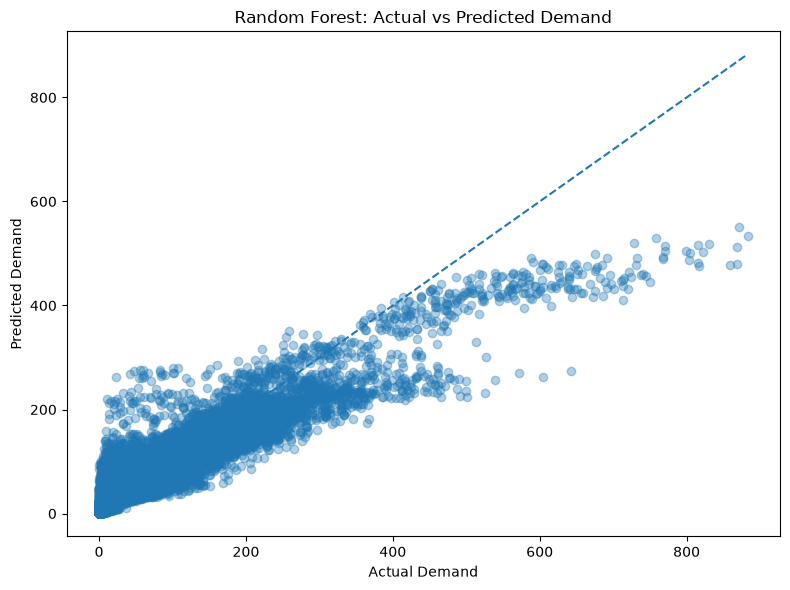

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.35
)

# Ideal prediction reference line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Demand")
plt.ylabel("Predicted Demand")
plt.title("Random Forest: Actual vs Predicted Demand")

plt.tight_layout()
plt.show()

In [16]:
# Get transformed feature names after one-hot encoding
feature_names = (
    model_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get Random Forest feature importance
importances = (
    model_pipeline
    .named_steps["regressor"]
    .feature_importances_
)

# Create feature importance DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sort and display top 15
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(15).to_string(index=False))

                              Feature  Importance
           numerical__shelf_life_days    0.276732
numerical__days_remaining_at_purchase    0.216195
          numerical__initial_quantity    0.167603
   categorical__category_Ready_to_Eat    0.075349
      numerical__spoilage_sensitivity    0.059430
              numerical__storage_temp    0.028508
                numerical__base_price    0.017436
                numerical__cost_price    0.014361
categorical__category_Pharmaceuticals    0.014329
   categorical__category_Frozen_Meals    0.012026
         categorical__category_Bakery    0.011563
               numerical__day_of_week    0.007835
        categorical__category_Seafood    0.007772
     categorical__product_name_Salads    0.007418
      categorical__product_name_Sushi    0.007117


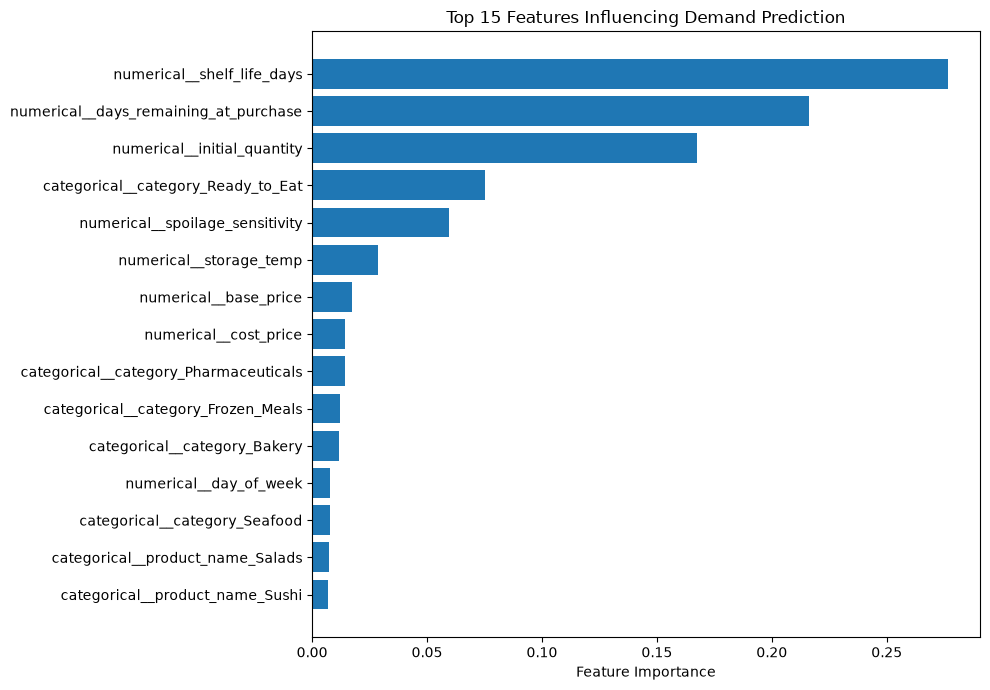

In [17]:
top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.title("Top 15 Features Influencing Demand Prediction")

plt.tight_layout()
plt.show()

In [18]:
print("TRAINING DEMAND")
print("Maximum:", y_train.max())
print("95th percentile:", y_train.quantile(0.95))
print("99th percentile:", y_train.quantile(0.99))

print("\nTESTING DEMAND")
print("Maximum:", y_test.max())
print("95th percentile:", y_test.quantile(0.95))
print("99th percentile:", y_test.quantile(0.99))

print(
    "\nTest records above training maximum:",
    (y_test > y_train.max()).sum()
)

TRAINING DEMAND
Maximum: 1118
95th percentile: 234.0
99th percentile: 459.0

TESTING DEMAND
Maximum: 883
95th percentile: 224.0
99th percentile: 442.97999999999956

Test records above training maximum: 0


In [19]:
error_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

error_df["Absolute_Error"] = (
    error_df["Actual"] - error_df["Predicted"]
).abs()

error_df["Demand_Range"] = pd.cut(
    error_df["Actual"],
    bins=[-1, 50, 100, 200, 400, float("inf")],
    labels=[
        "0-50",
        "51-100",
        "101-200",
        "201-400",
        "Above 400"
    ]
)

range_performance = error_df.groupby(
    "Demand_Range",
    observed=True
).agg(
    Records=("Actual", "count"),
    Average_Actual=("Actual", "mean"),
    Average_Predicted=("Predicted", "mean"),
    MAE=("Absolute_Error", "mean")
)

print(range_performance.round(2))

              Records  Average_Actual  Average_Predicted     MAE
Demand_Range                                                    
0-50            15502           15.68              28.10   13.48
51-100           4523           72.40              78.16   17.24
101-200          3469          139.51             130.12   24.42
201-400          1275          263.20             213.23   57.46
Above 400         334          536.13             387.41  148.75


In [20]:
error_df["Prediction_Error"] = (
    error_df["Predicted"] - error_df["Actual"]
)

bias_analysis = error_df.groupby(
    "Demand_Range",
    observed=True
).agg(
    Records=("Actual", "count"),
    Average_Actual=("Actual", "mean"),
    Average_Predicted=("Predicted", "mean"),
    Mean_Error=("Prediction_Error", "mean"),
    MAE=("Absolute_Error", "mean")
)

print(bias_analysis.round(2))

              Records  Average_Actual  Average_Predicted  Mean_Error     MAE
Demand_Range                                                                
0-50            15502           15.68              28.10       12.42   13.48
51-100           4523           72.40              78.16        5.77   17.24
101-200          3469          139.51             130.12       -9.39   24.42
201-400          1275          263.20             213.23      -49.97   57.46
Above 400         334          536.13             387.41     -148.71  148.75


In [21]:
correlation = (
    df[numerical_features + ["daily_demand"]]
    .corr(numeric_only=True)["daily_demand"]
    .drop("daily_demand")
    .sort_values(key=abs, ascending=False)
)

print("Correlation with daily demand:")
print(correlation.round(3))



Correlation with daily demand:
initial_quantity              0.388
shelf_life_days              -0.300
days_remaining_at_purchase   -0.298
spoilage_sensitivity          0.281
storage_temp                  0.217
base_price                   -0.179
cost_price                   -0.177
is_weekend                    0.079
day_of_week                   0.063
month                        -0.016
is_promoted                  -0.008
handling_score               -0.005
temp_deviation               -0.002
distribution_hours           -0.002
temp_abuse_events             0.001
supplier_score               -0.001
packaging_score               0.000
Name: daily_demand, dtype: float64


In [22]:
import os
import joblib

# Create model directory
os.makedirs("models", exist_ok=True)

# Save trained pipeline
joblib.dump(
    model_pipeline,
    "models/random_forest_baseline.pkl"
)

print("Baseline Random Forest model saved successfully!")

Baseline Random Forest model saved successfully!


In [23]:
baseline_results = pd.DataFrame({
    "Model": ["Random Forest Baseline"],
    "MAE": [mae],
    "RMSE": [rmse],
    "R2": [r2]
})

os.makedirs("results", exist_ok=True)

baseline_results.to_csv(
    "results/baseline_metrics.csv",
    index=False
)

print(baseline_results)

                    Model        MAE       RMSE        R2
0  Random Forest Baseline  19.704091  34.513367  0.847357


In [24]:
baseline_results = pd.DataFrame({
    "Model": ["Random Forest Baseline"],
    "MAE": [mae],
    "RMSE": [rmse],
    "R2": [r2]
})

os.makedirs("results", exist_ok=True)

baseline_results.to_csv(
    "results/baseline_metrics.csv",
    index=False
)

print(baseline_results)

                    Model        MAE       RMSE        R2
0  Random Forest Baseline  19.704091  34.513367  0.847357


In [25]:
import joblib

model_path = "models/random_forest_model.pkl"

pipeline = joblib.load(model_path)

print("Model loaded successfully!")
print("\nPipeline steps:")
print(pipeline.named_steps)

FileNotFoundError: [Errno 2] No such file or directory: 'models/random_forest_model.pkl'

In [26]:
import os

print("Current directory:")
print(os.getcwd())

print("\nModels folder contents:")
print(os.listdir("models"))

Current directory:
d:\M_tech\sem 3\BDA\Freshflow\notebooks

Models folder contents:
['random_forest_baseline.pkl']


In [27]:
import joblib

model_path = "../models/random_forest_baseline.pkl"

pipeline = joblib.load(model_path)

print("Model loaded successfully!")

print("\nPipeline steps:")
print(pipeline.named_steps)

FileNotFoundError: [Errno 2] No such file or directory: '../models/random_forest_baseline.pkl'

In [28]:
import os

project_path = os.path.dirname(os.getcwd())

print("Project path:", project_path)

print("\nSearching for saved model...")

for root, dirs, files in os.walk(project_path):
    for file in files:
        if file.endswith(".pkl"):
            print(os.path.join(root, file))

            

Project path: d:\M_tech\sem 3\BDA\Freshflow

Searching for saved model...
d:\M_tech\sem 3\BDA\Freshflow\.venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_pickle_py27_np17.pkl
d:\M_tech\sem 3\BDA\Freshflow\.venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_pickle_py33_np18.pkl
d:\M_tech\sem 3\BDA\Freshflow\.venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_pickle_py34_np19.pkl
d:\M_tech\sem 3\BDA\Freshflow\.venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_pickle_py35_np19.pkl
d:\M_tech\sem 3\BDA\Freshflow\.venv\Lib\site-packages\joblib\test\data\joblib_0.11.0_pickle_py36_np111.pkl
d:\M_tech\sem 3\BDA\Freshflow\.venv\Lib\site-packages\joblib\test\data\joblib_0.9.2_pickle_py27_np16.pkl
d:\M_tech\sem 3\BDA\Freshflow\.venv\Lib\site-packages\joblib\test\data\joblib_0.9.2_pickle_py27_np17.pkl
d:\M_tech\sem 3\BDA\Freshflow\.venv\Lib\site-packages\joblib\test\data\joblib_0.9.2_pickle_py33_np18.pkl
d:\M_tech\sem 3\BDA\Freshflow\.venv\Lib\site-packages\joblib\test\data\joblib_0.

In [29]:
import joblib

model_path = "models/random_forest_baseline.pkl"

pipeline = joblib.load(model_path)

print("Model loaded successfully!")
print("\nPipeline steps:")
print(pipeline.named_steps)

Model loaded successfully!

Pipeline steps:
{'preprocessor': ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['product_name', 'category', 'store_id',
                                  'region']),
                                ('numerical', 'passthrough',
                                 ['shelf_life_days',
                                  'days_remaining_at_purchase', 'storage_temp',
                                  'temp_deviation', 'base_price', 'cost_price',
                                  'initial_quantity', 'spoilage_sensitivity',
                                  'day_of_week', 'is_weekend', 'month',
                                  'temp_abuse_events', 'distribution_hours',
                                  'handling_score', 'packaging_score',
                                  'supplier_score', 'is_promoted'])]), 'regressor': RandomForestRegressor(max_depth=12, max_fe